In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

## Z- Score


In [3]:
df = pd.read_csv('/home/lucky/Machine_Learning/datasets/placement.csv')


In [4]:
df.head()

,cgpa,placement_exam_marks,placed
0,7.19,26.0,1
1,7.46,38.0,1
2,7.54,40.0,1
3,6.42,8.0,1
4,7.23,17.0,0


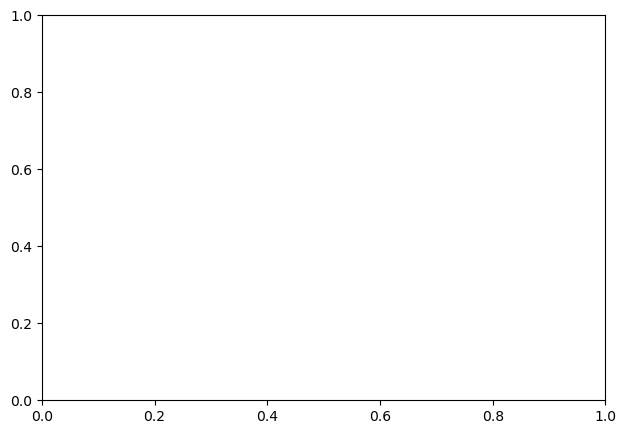

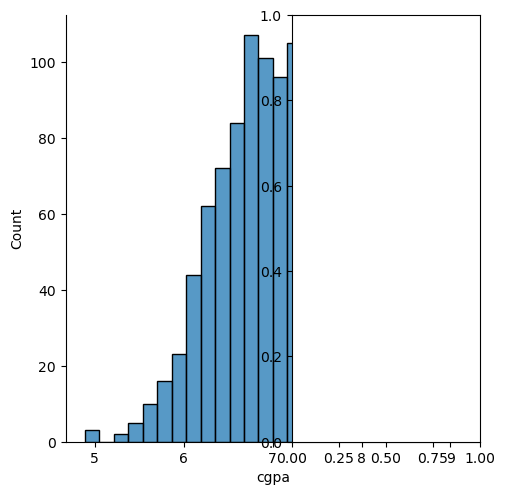

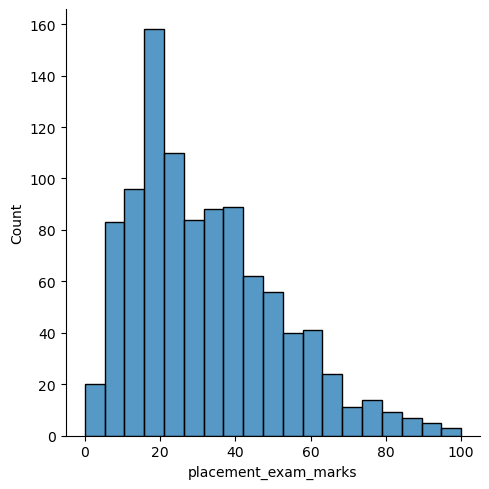

In [5]:
plt.figure(figsize=(16,5))
plt.subplot(1,2,1)
sns.displot(df['cgpa'])

plt.subplot(1,2,2)
sns.displot(df['placement_exam_marks'])

plt.show()

## InterQuartile Handling

In [6]:
df.shape

(1000, 3)

In [7]:
df.sample(5)

,cgpa,placement_exam_marks,placed
222,6.97,78.0,0
504,7.24,25.0,0
801,6.31,14.0,0
457,6.58,20.0,0
316,7.07,38.0,1


In [8]:
df['cgpa'].skew()

np.float64(-0.014529938929314918)

In [9]:
df['placement_exam_marks'].describe()

count    1000.000000
mean       32.225000
std        19.130822
min         0.000000
25%        17.000000
50%        28.000000
75%        44.000000
max       100.000000
Name: placement_exam_marks, dtype: float64

<Axes: ylabel='placement_exam_marks'>

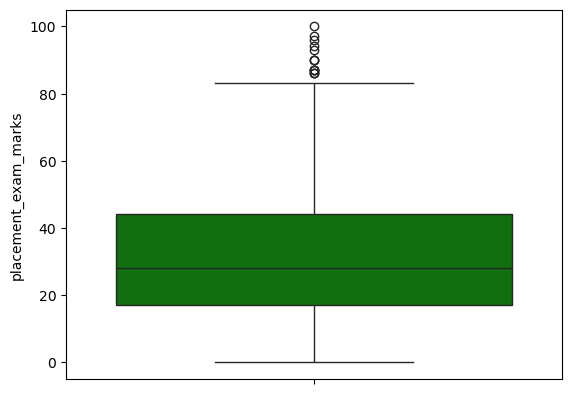

In [ ]:
sns.boxplot(df['placement_exam_marks'], color='green')

In [12]:
#finding the IQR
percentile25 = df['placement_exam_marks'].quantile(0.25)
percentile75 = df['placement_exam_marks'].quantile(0.75)

In [13]:
percentile25, percentile75

(np.float64(17.0), np.float64(44.0))

In [14]:
iqr = percentile75 - percentile25

In [15]:
iqr

np.float64(27.0)

In [16]:
upper_limit = percentile75 + (1.5 * iqr)
lower_limit = percentile25 - (1.5 * iqr)

In [18]:
print("Upper Limit: ", upper_limit)
print("Lower Limit: ", lower_limit)

Upper Limit:  84.5
Lower Limit:  -23.5


In [19]:
## finding the outliers

df[df['placement_exam_marks'] > upper_limit]

,cgpa,placement_exam_marks,placed
9,7.75,94.0,1
40,6.60,86.0,1
61,7.51,86.0,0
134,6.33,93.0,0
162,7.80,90.0,0
283,7.09,87.0,0
290,8.38,87.0,0
311,6.97,87.0,1
324,6.64,90.0,0
630,6.56,96.0,1


In [20]:
df[df['placement_exam_marks'] < lower_limit]

,cgpa,placement_exam_marks,placed


## Trimming

In [21]:
new_df = df[df['placement_exam_marks'] < upper_limit]

In [22]:
new_df.shape

(985, 3)

<Axes: ylabel='placement_exam_marks'>

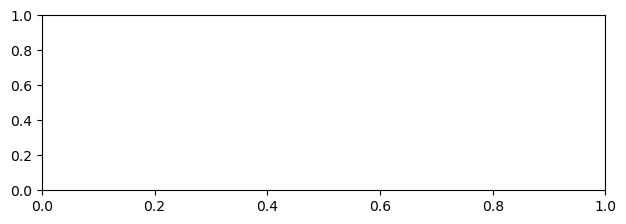

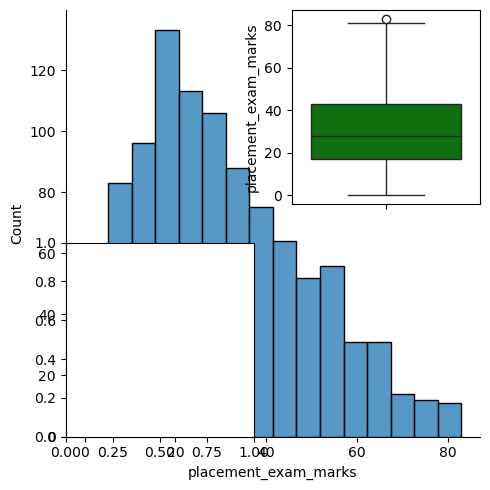

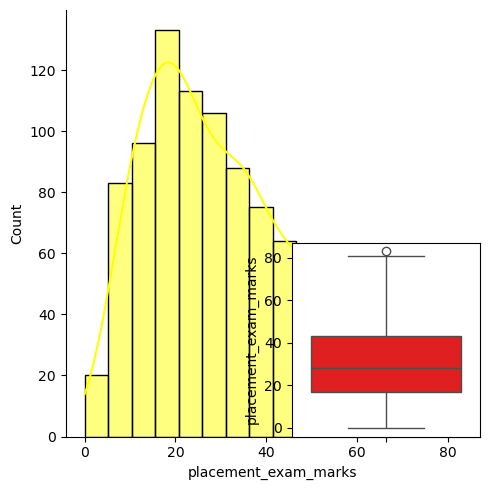

In [24]:
plt.figure(figsize=(16,5))
plt.subplot(2,2,1)
sns.displot(new_df['placement_exam_marks'])

plt.subplot(2,2,2)
sns.boxplot(new_df['placement_exam_marks'], color='green')

plt.subplot(2,2,3)
sns.displot(new_df['placement_exam_marks'], kde=True, color='yellow')

plt.subplot(2,2,4)
sns.boxplot(new_df['placement_exam_marks'], color='red')
